<a href="https://colab.research.google.com/github/AhmadSyahreza/Katanya-kami-lomba/blob/main/gataulawe_peningaku.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import pandas as pd, numpy as np, lightgbm as lgb
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

SEED = 2026
np.random.seed(SEED)
print("Seed set:", SEED)

Seed set: 2026


In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
BASE = "/content/drive/MyDrive/Lomba Data/"
train         = pd.read_csv(BASE + "train.csv")
test_history  = pd.read_csv(BASE + "test_history.csv")
test          = pd.read_csv(BASE + "test.csv")
movies        = pd.read_csv(BASE + "movies.csv")
ticket_prices = pd.read_csv(BASE + "ticket_prices.csv")
holidays      = pd.read_csv(BASE + "holidays.csv")
sample_sub    = pd.read_csv(BASE + "sample_submission.csv")

for df in [train, test_history, test]:
    df["date_show"] = pd.to_datetime(df["date_show"])
holidays["date"] = pd.to_datetime(holidays["date"])

target_cols = [f"target_{i}" for i in range(4, 11)]
K = ["movie_title", "cinema_ids"]

print(f"Train       : {train.shape}")
print(f"Test        : {test.shape}")
print(f"Test history: {test_history.shape}")
print(f"Train range : {train['date_show'].min().date()} → {train['date_show'].max().date()}")
print(f"Test range  : {test['date_show'].min().date()} → {test['date_show'].max().date()}")

Train       : (138959, 7)
Test        : (72611, 5)
Test history: (32323, 7)
Train range : 2025-04-01 → 2025-09-30
Test range  : 2025-10-04 → 2026-03-27


In [39]:
def mase(y_true, y_pred, scale):
    """Mean Absolute Scaled Error"""
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    scale  = np.asarray(scale, float)
    return float(np.mean(np.abs(y_true - y_pred) / scale))

In [40]:
# Rata-rata tiket per baris di train vs test_history
train_mean = train["total_ticket"].mean()
test_mean  = test_history["total_ticket"].mean()

# Rata-rata 3 hari pertama per (film, bioskop)
train_first3 = (train.groupby(K).head(3)
                .groupby(K)["total_ticket"].mean())
test_first3  = (test_history.groupby(K).head(3)
                .groupby(K)["total_ticket"].mean())

print(f"Train mean all    : {train_mean:.2f}")
print(f"Test  mean all    : {test_mean:.2f}")
print(f"Ratio             : {test_mean/train_mean:.2f}")
print()
print(f"Train first3 mean : {train_first3.mean():.2f}")
print(f"Test  first3 mean : {test_first3.mean():.2f}")
print(f"Ratio first3      : {test_first3.mean()/train_first3.mean():.2f}")

Train mean all    : 354.12
Test  mean all    : 224.43
Ratio             : 0.63

Train first3 mean : 304.02
Test  first3 mean : 208.91
Ratio first3      : 0.69


In [41]:
train_movies = set(train["movie_title"].unique())
test_movies  = set(test["movie_title"].unique())

overlap = train_movies & test_movies
only_test = test_movies - train_movies

print(f"Film train    : {len(train_movies)}")
print(f"Film test     : {len(test_movies)}")
print(f"Overlap       : {len(overlap)}")
print(f"Hanya di test : {len(only_test)}")
print()
print("Contoh film yang hanya ada di test:")
for m in list(only_test)[:10]:
    print(f"  - {m}")

Film train    : 237
Film test     : 160
Overlap       : 10
Hanya di test : 150

Contoh film yang hanya ada di test:
  - QORIN 2
  - MERCY
  - OZORA: PENGANIAYAAN BRUTAL PENGUASA JAKSEL
  - WICKED: FOR GOOD (3D)
  - MERTUA NGERI KALI
  - PREDATOR: BADLANDS (3D)
  - GOOD LUCK, HAVE FUN, DONT DIE
  - MODUAL NEKAD
  - AVATAR: FIRE AND ASH
  - RAJAH


In [42]:
def build_windows(df):
    rows = []
    for (film, bioskop), g in df.groupby(K):
        g = g.sort_values("date_show").reset_index(drop=True)
        if len(g) < 10: continue
        w = g.iloc[:10]
        if (w["date_show"].diff()[1:] != pd.Timedelta(days=1)).any():
            continue  # skip kalau tanggal tidak berurutan
        r = {"movie_title": film, "cinema_ids": bioskop,
             "city_name": w["city_name"].iloc[0],
             "date_D1" : w["date_show"].iloc[0]}
        for k in range(3):
            r[f"d{k+1}"]     = w["total_ticket"].iloc[k]
            r[f"occ_{k+1}"]  = w["occupation_rate"].iloc[k]
            r[f"show_{k+1}"] = w["total_show"].iloc[k]
        for i in range(3, 10):
            r[f"target_{i+1}"] = w["total_ticket"].iloc[i]
            r[f"date_D{i+1}"]  = w["date_show"].iloc[i]
        rows.append(r)
    return pd.DataFrame(rows)

windows = build_windows(train)
print(f"Windows shape : {windows.shape}")
print(f"Kolom         : {windows.columns.tolist()[:10]}...")

Windows shape : (3634, 27)
Kolom         : ['movie_title', 'cinema_ids', 'city_name', 'date_D1', 'd1', 'occ_1', 'show_1', 'd2', 'occ_2', 'show_2']...


In [43]:
def base_feats(df):
    df = df.copy()
    df["avg_d1_d3"]    = df[["d1","d2","d3"]].mean(axis=1)
    df["max_d1_d3"]    = df[["d1","d2","d3"]].max(axis=1)
    df["min_d1_d3"]    = df[["d1","d2","d3"]].min(axis=1)
    df["trend_d1_d3"]  = (df["d3"] - df["d1"]) / (df["avg_d1_d3"] + 1)
    df["ratio_d3_d1"]  = df["d3"] / (df["d1"] + 1)
    df["occ_avg"]      = df[["occ_1","occ_2","occ_3"]].mean(axis=1)
    df["occ_max"]      = df[["occ_1","occ_2","occ_3"]].max(axis=1)
    df["occ_trend"]    = df["occ_3"] - df["occ_1"]
    df["show_avg"]     = df[["show_1","show_2","show_3"]].mean(axis=1)
    df["seat_per_show"]= df["avg_d1_d3"] / (df["show_avg"] + 1)
    df["dow_d1"]       = pd.to_datetime(df["date_D1"]).dt.dayofweek
    df["month_d1"]     = pd.to_datetime(df["date_D1"]).dt.month
    df["is_weekend_d1"]= (df["dow_d1"] >= 4).astype(int)
    df["scale"]        = df["avg_d1_d3"].clip(lower=1)  # untuk MASE
    return df

windows = base_feats(windows)
print("Fitur setelah base_feats:", windows.shape[1])

Fitur setelah base_feats: 41


In [44]:
# Lookup tanggal libur
hol_lookup = holidays.drop_duplicates("date").set_index("date")
holiday_dates = set(hol_lookup.index[hol_lookup["holiday_tipe"] == "holiday"])

def add_target_calendar(df):
    df = df.copy()
    for i in range(4, 11):
        dc = f"date_D{i}"
        if dc not in df.columns:
            df[dc] = pd.NaT
        dt = pd.to_datetime(df[dc])
        df[f"dow_D{i}"]        = dt.dt.dayofweek.fillna(-1).astype(int)
        df[f"is_weekend_D{i}"] = (df[f"dow_D{i}"] >= 4).astype(int)
        df[f"is_holiday_D{i}"] = dt.isin(holiday_dates).astype(int)
    return df

windows = add_target_calendar(windows)
print("Fitur setelah calendar:", windows.shape[1])

Fitur setelah calendar: 62


In [45]:
movies_u  = movies.drop_duplicates("original_title")[["original_title","genre","age_rating"]]
prices    = (ticket_prices.groupby("city_name", as_index=False)["ceil"]
             .mean().rename(columns={"ceil":"ticket_price"}))
hol_merge = holidays.drop_duplicates("date")[["date","day_tipe","holiday_tipe"]]

def enrich(df):
    df = df.merge(movies_u, left_on="movie_title", right_on="original_title", how="left")
    df["genre_main"] = df["genre"].fillna("Unknown").str.split(",").str[0].str.strip().fillna("Unknown")
    df["age_rating"] = df["age_rating"].fillna("Unknown")
    df = df.merge(prices, on="city_name", how="left")
    df["ticket_price"] = df["ticket_price"].fillna(df["ticket_price"].median())
    df = df.merge(hol_merge, left_on="date_D1", right_on="date", how="left")
    df["day_tipe"]     = df["day_tipe"].fillna("weekday")
    df["holiday_tipe"] = df["holiday_tipe"].fillna("normal")
    df["is_holiday_d1"]= (df["holiday_tipe"] == "holiday").astype(int)
    return df

windows = enrich(windows)
print("Fitur setelah enrich:", windows.shape[1])

Fitur setelah enrich: 71


In [46]:
def cluster_feats(df):
    df = df.copy()
    df["date_D1"] = pd.to_datetime(df["date_D1"])
    df["week_start"] = df["date_D1"] - pd.to_timedelta(df["date_D1"].dt.dayofweek, unit="D")
    agg = (df.groupby(["cinema_ids","week_start"])
             .agg(c_d1=("d1","sum"), c_d2=("d2","sum"), c_d3=("d3","sum"),
                  c_avg=("avg_d1_d3","sum"), c_cnt=("avg_d1_d3","size"))
             .reset_index())
    df = df.merge(agg, on=["cinema_ids","week_start"], how="left")
    df["c_other_cnt"]      = (df["c_cnt"] - 1).clip(lower=1)
    df["c_other_avg_d1"]   = (df["c_d1"] - df["d1"]) / df["c_other_cnt"]
    df["c_other_avg_d2"]   = (df["c_d2"] - df["d2"]) / df["c_other_cnt"]
    df["c_other_avg_d3"]   = (df["c_d3"] - df["d3"]) / df["c_other_cnt"]
    df["c_other_avg_d1d3"] = (df["c_avg"] - df["avg_d1_d3"]) / df["c_other_cnt"]
    df["share_in_cluster"] = df["avg_d1_d3"] / (df["c_other_avg_d1d3"] + 1)
    for c in ["c_other_avg_d1","c_other_avg_d2","c_other_avg_d3",
              "c_other_avg_d1d3","share_in_cluster"]:
        df[c] = df[c].fillna(0)
    return df.drop(columns=["c_d1","c_d2","c_d3","c_avg","c_cnt","week_start"])

windows = cluster_feats(windows)
print("Fitur setelah cluster:", windows.shape[1])

Fitur setelah cluster: 77


In [47]:
windows = windows.sort_values("date_D1").reset_index(drop=True)
cutoff  = windows["date_D1"].quantile(0.75)
tr_mask = (windows["date_D1"] < cutoff).values

tr_df = windows[tr_mask].reset_index(drop=True)
va_df = windows[~tr_mask].reset_index(drop=True)
print(f"Cutoff    : {cutoff.date()}")
print(f"Train     : {len(tr_df)}")
print(f"Valid     : {len(va_df)}")

Cutoff    : 2025-08-07
Train     : 2667
Valid     : 967


In [48]:
def compute_te(tr_df, other_df, key="movie_title", n_splits=5, smooth=20):
    tr, oth = tr_df.copy(), other_df.copy()
    for t in target_cols:
        tr[f"rate_{t}"] = tr[t] / tr["scale"]
    g_mean = {t: tr[f"rate_{t}"].mean() for t in target_cols}
    cnt    = tr.groupby(key).size()
    for t in target_cols:
        m  = tr.groupby(key)[f"rate_{t}"].mean()
        sm = (m * cnt + g_mean[t] * smooth) / (cnt + smooth)
        oth[f"te_rate_{t}"] = oth[key].map(sm).fillna(g_mean[t])
    for t in target_cols:
        tr[f"te_rate_{t}"] = np.nan
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for i_tr, i_va in kf.split(tr):
        sub, sub_va = tr.iloc[i_tr], tr.iloc[i_va]
        s_cnt = sub.groupby(key).size()
        s_g   = {t: sub[f"rate_{t}"].mean() for t in target_cols}
        for t in target_cols:
            m  = sub.groupby(key)[f"rate_{t}"].mean()
            sm = (m * s_cnt + s_g[t] * smooth) / (s_cnt + smooth)
            tr.loc[sub_va.index, f"te_rate_{t}"] = sub_va[key].map(sm).fillna(s_g[t]).values
    return tr, oth

tr_df, va_df = compute_te(tr_df, va_df)
print("TE selesai. Contoh te_rate_target_5:")
print(tr_df[["movie_title","te_rate_target_5"]].head())

TE selesai. Contoh te_rate_target_5:
         movie_title  te_rate_target_5
0  PABRIK GULA UNCUT          1.218452
1  PABRIK GULA UNCUT          1.206213
2  PABRIK GULA UNCUT          1.218452
3  PABRIK GULA UNCUT          1.228853
4  PABRIK GULA UNCUT          1.228853


In [49]:
cat_cols = ["city_name","age_rating","genre_main","day_tipe","holiday_tipe"]
te_cols  = [f"te_rate_{t}" for t in target_cols]
num_cols = ["d1","d2","d3","avg_d1_d3","max_d1_d3","min_d1_d3",
            "trend_d1_d3","ratio_d3_d1","occ_avg","occ_max","occ_trend",
            "show_avg","seat_per_show","dow_d1","month_d1","is_weekend_d1",
            "is_holiday_d1","ticket_price",
            "c_other_avg_d1","c_other_avg_d2","c_other_avg_d3",
            "c_other_avg_d1d3","share_in_cluster"]
for i in range(4, 11):
    num_cols += [f"dow_D{i}", f"is_weekend_D{i}", f"is_holiday_D{i}"]

feat_cols = cat_cols + num_cols + te_cols
print(f"Total fitur: {len(feat_cols)}")

for c in cat_cols:
    tr_df[c] = tr_df[c].astype("category")
    va_df[c] = pd.Categorical(va_df[c], categories=tr_df[c].cat.categories)

X_tr = tr_df[feat_cols].copy()
X_va = va_df[feat_cols].copy()
y_tr = tr_df[target_cols].values
y_va = va_df[target_cols].values
scale_va = va_df["scale"].values

print(f"X_tr: {X_tr.shape} | X_va: {X_va.shape}")

Total fitur: 56
X_tr: (2667, 56) | X_va: (967, 56)


In [50]:
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              num_leaves=63, min_data_in_leaf=20, feature_fraction=0.85,
              bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
              seed=SEED, verbosity=-1)

models, best_iters = {}, {}
pred_va = np.zeros((len(X_va), len(target_cols)))

for j, t in enumerate(target_cols):
    dtr = lgb.Dataset(X_tr, y_tr[:, j], categorical_feature=cat_cols)
    dva = lgb.Dataset(X_va, y_va[:, j], reference=dtr)
    m = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    models[t] = m
    best_iters[t] = m.best_iteration
    pred_va[:, j] = m.predict(X_va, num_iteration=m.best_iteration)
    print(f"  {t}: iter={m.best_iteration:>4d}")
pred_va = np.clip(pred_va, 0, None)
print("\nTraining selesai.")

  target_4: iter= 132
  target_5: iter= 434
  target_6: iter=  75
  target_7: iter=  40
  target_8: iter=  65
  target_9: iter=  54
  target_10: iter=  31

Training selesai.


# RATIO CAL

In [51]:
# === STEP A: Build ratio target di train & valid ===
for t in target_cols:
    tr_df[f"ratio_{t}"] = tr_df[t] / tr_df["scale"]
    va_df[f"ratio_{t}"] = va_df[t] / va_df["scale"]

ratio_cols = [f"ratio_{t}" for t in target_cols]

# === STEP B: Train 7 model pada ratio (bukan magnitude) ===
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              num_leaves=63, min_data_in_leaf=20, feature_fraction=0.85,
              bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
              seed=SEED, verbosity=-1)

models_ratio, best_iters_ratio = {}, {}
pred_va_ratio = np.zeros((len(X_va), len(target_cols)))

for j, rc in enumerate(ratio_cols):
    y_tr_j = tr_df[rc].values
    y_va_j = va_df[rc].values
    dtr = lgb.Dataset(X_tr, y_tr_j, categorical_feature=cat_cols)
    dva = lgb.Dataset(X_va, y_va_j, reference=dtr)
    m = lgb.train(params, dtr, num_boost_round=2000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    models_ratio[rc] = m
    best_iters_ratio[rc] = m.best_iteration
    pred_va_ratio[:, j] = m.predict(X_va, num_iteration=m.best_iteration)
    print(f"  {rc}: iter={m.best_iteration:>4d}")

# Convert ratio predictions back to magnitude untuk cek MASE
pred_va_ratio_as_mag = pred_va_ratio * scale_va[:, None]
pred_va_ratio_as_mag = np.clip(pred_va_ratio_as_mag, 0, None)

# === STEP C: Kalibrasi per-hari pada ratio-space ===
alpha_ratio = {}
pred_va_ratio_cal = pred_va_ratio.copy()
for j, rc in enumerate(ratio_cols):
    best_a, best_m = 1.0, 1e9
    for a in np.linspace(0.7, 1.3, 61):
        p = np.clip(pred_va_ratio[:, j] * a, 0, None) * scale_va
        m = np.mean(np.abs(va_df[target_cols[j]].values - p) / scale_va)
        if m < best_m: best_m, best_a = m, a
    alpha_ratio[rc] = best_a
    pred_va_ratio_cal[:, j] = np.clip(pred_va_ratio[:, j] * best_a, 0, None)

pred_va_ratio_cal_mag = np.clip(pred_va_ratio_cal * scale_va[:, None], 0, None)

mase_ratio_raw = mase(y_va.reshape(-1), pred_va_ratio_as_mag.reshape(-1),
                      np.repeat(scale_va, len(target_cols)))
mase_ratio_cal = mase(y_va.reshape(-1), pred_va_ratio_cal_mag.reshape(-1),
                      np.repeat(scale_va, len(target_cols)))

print(f"\n=== PERBANDINGAN MODEL ===")
print(f"Magnitude model + alpha per-hari : 0.3066")
print(f"Ratio model raw                  : {mase_ratio_raw:.4f}")
print(f"Ratio model + alpha per-hari     : {mase_ratio_cal:.4f}")

# === STEP D: Prediksi Test di ratio-space ===
pred_te_ratio = np.zeros((len(X_te_full), len(target_cols)))
for j, rc in enumerate(ratio_cols):
    pred_te_ratio[:, j] = models_ratio[rc].predict(X_te_full,
                                                   num_iteration=best_iters_ratio[rc])
pred_te_ratio = np.clip(pred_te_ratio, 0, None)

# Apply alpha
pred_te_ratio_cal = np.zeros_like(pred_te_ratio)
for j, rc in enumerate(ratio_cols):
    pred_te_ratio_cal[:, j] = np.clip(pred_te_ratio[:, j] * alpha_ratio[rc], 0, None)

# Convert ke magnitude
scale_te = X_te["scale"].values
pred_te_mag = np.clip(pred_te_ratio_cal * scale_te[:, None], 0, None)

print(f"\nPrediksi ratio test (median per hari):")
for j, rc in enumerate(ratio_cols):
    med = np.median(pred_te_ratio_cal[:, j])
    print(f"  {rc}: median ratio = {med:.3f}")

# === STEP E: Cek profile ===
train_prof = [(tr_df[t]/tr_df["scale"]).median() for t in target_cols]
test_prof = [np.median(pred_te_ratio_cal[:, j]) for j in range(len(target_cols))]

print(f"\nHari | Train Profile | Test Ratio Pred | Ratio")
for i, t in enumerate(target_cols):
    r = test_prof[i] / train_prof[i] if train_prof[i] > 0 else 0
    print(f"{t} | {train_prof[i]:.3f} | {test_prof[i]:.3f} | {r:.3f}")

  ratio_target_4: iter= 107
  ratio_target_5: iter= 346
  ratio_target_6: iter= 397
  ratio_target_7: iter= 152
  ratio_target_8: iter= 140
  ratio_target_9: iter= 109
  ratio_target_10: iter= 119

=== PERBANDINGAN MODEL ===
Magnitude model + alpha per-hari : 0.3066
Ratio model raw                  : 0.3217
Ratio model + alpha per-hari     : 0.3013

Prediksi ratio test (median per hari):
  ratio_target_4: median ratio = 1.284
  ratio_target_5: median ratio = 0.878
  ratio_target_6: median ratio = 0.645
  ratio_target_7: median ratio = 0.824
  ratio_target_8: median ratio = 0.792
  ratio_target_9: median ratio = 0.640
  ratio_target_10: median ratio = 0.668

Hari | Train Profile | Test Ratio Pred | Ratio
target_4 | 1.119 | 1.284 | 1.147
target_5 | 1.017 | 0.878 | 0.863
target_6 | 0.789 | 0.645 | 0.817
target_7 | 0.715 | 0.824 | 1.153
target_8 | 0.608 | 0.792 | 1.302
target_9 | 0.606 | 0.640 | 1.055
target_10 | 0.613 | 0.668 | 1.090


In [52]:
imp = pd.DataFrame({
    "feature": models["target_5"].feature_name(),
    "gain":    models["target_5"].feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)

print("Top 15 fitur untuk model target_5 (D5):")
print(imp.head(15).to_string(index=False))

Top 15 fitur untuk model target_5 (D5):
          feature         gain
               d3 2.467282e+10
        avg_d1_d3 5.034478e+09
         show_avg 3.621530e+09
        max_d1_d3 1.797208e+09
               d2 8.787477e+08
 te_rate_target_5 8.037800e+08
 te_rate_target_4 7.505370e+08
        min_d1_d3 3.685084e+08
 te_rate_target_9 1.583380e+08
        occ_trend 1.428709e+08
               d1 1.141757e+08
    seat_per_show 8.717948e+07
te_rate_target_10 7.612283e+07
   c_other_avg_d2 6.481637e+07
 te_rate_target_8 5.848897e+07


In [53]:
alphas = np.linspace(0.7, 1.4, 71)
best_a_global, best_m_global = 1.0, 1e9
for a in alphas:
    p = np.clip(pred_va * a, 0, None)
    m = mase(y_va.reshape(-1), p.reshape(-1), np.repeat(scale_va, len(target_cols)))
    if m < best_m_global: best_m_global, best_a_global = m, a

raw_mase = mase(y_va.reshape(-1), pred_va.reshape(-1),
                np.repeat(scale_va, len(target_cols)))

print(f"MASE raw        : {raw_mase:.4f}")
print(f"Best alpha      : {best_a_global:.3f}")
print(f"MASE calibrated : {best_m_global:.4f}")

MASE raw        : 0.4962
Best alpha      : 0.700
MASE calibrated : 0.3607


In [54]:
alpha_per_day = {}
pred_va_cal = pred_va.copy()

for j, t in enumerate(target_cols):
    best_a, best_m = 1.0, 1e9
    for a in np.linspace(0.4, 1.5, 111):
        p = np.clip(pred_va[:, j] * a, 0, None)
        m = np.mean(np.abs(y_va[:, j] - p) / scale_va)
        if m < best_m: best_m, best_a = m, a
    alpha_per_day[t] = best_a
    pred_va_cal[:, j] = np.clip(pred_va[:, j] * best_a, 0, None)
    print(f"  {t}: alpha={best_a:.3f}  MASE_j={best_m:.4f}")

mase_perday = mase(y_va.reshape(-1), pred_va_cal.reshape(-1),
                   np.repeat(scale_va, len(target_cols)))
print(f"\nMASE per-day calibrated : {mase_perday:.4f}")

  target_4: alpha=0.910  MASE_j=0.3287
  target_5: alpha=0.750  MASE_j=0.3766
  target_6: alpha=0.600  MASE_j=0.2601
  target_7: alpha=0.420  MASE_j=0.2727
  target_8: alpha=0.550  MASE_j=0.2710
  target_9: alpha=0.520  MASE_j=0.2934
  target_10: alpha=0.400  MASE_j=0.3435

MASE per-day calibrated : 0.3066


In [55]:
# Hitung profile median per genre per hari di TRAIN
tr_df_copy = tr_df.copy()
for j, t in enumerate(target_cols):
    tr_df_copy[f"profile_{t}"] = tr_df_copy[t] / tr_df_copy["scale"]

print("Profile (median) per genre untuk beberapa hari:")
genre_profile = (tr_df_copy.groupby("genre_main")
                 [["profile_target_4","profile_target_5","profile_target_10"]]
                 .agg(["median","size"]))
print(genre_profile[genre_profile[("profile_target_4","size")] >= 20])

Profile (median) per genre untuk beberapa hari:
           profile_target_4      profile_target_5      profile_target_10     
                     median size           median size            median size
genre_main                                                                   
Action             1.143266  330         0.998237  330          0.355617  330
Adventure          2.452906   69         2.035121   69          1.645057   69
Animation          1.243151  201         1.332930  201          1.377016  201
Comedy             0.835020  103         0.714383  103          0.627809  103
Drama              1.165454  580         1.242463  580          0.995726  580
Horror             1.100031  948         0.900837  948          0.561926  948
Sport              1.110849   37         1.086128   37          0.471475   37
Superhero          1.307659   89         1.057946   89          0.286501   89
Thriller           0.911693   68         0.869783   68          0.465119   68
Unknown         

In [56]:
# Kalikan prediksi valid/test per genre sesuai ratio
global_profile = tr_df_copy[[f"profile_{t}" for t in target_cols]].median()
for j, t in enumerate(target_cols):
    genre_ratio = tr_df_copy.groupby("genre_main")[f"profile_{t}"].median() / global_profile[f"profile_{t}"]
    # Apply ke prediksi valid (dan nanti ke test)
    # ...

In [57]:
def build_test_windows(th, key_cols):
    th = th.sort_values("date_show").copy()
    first3 = th.groupby(key_cols).head(3).copy()
    first3["k"] = first3.groupby(key_cols).cumcount() + 1
    d_p = first3.pivot_table(index=key_cols, columns="k",
                             values="total_ticket", aggfunc="first").reset_index()
    d_p = d_p.rename(columns={1:"d1", 2:"d2", 3:"d3"})
    o_p = first3.pivot_table(index=key_cols, columns="k",
                             values="occupation_rate", aggfunc="first").reset_index()
    o_p = o_p.rename(columns={1:"occ_1", 2:"occ_2", 3:"occ_3"})
    s_p = first3.pivot_table(index=key_cols, columns="k",
                             values="total_show", aggfunc="first").reset_index()
    s_p = s_p.rename(columns={1:"show_1", 2:"show_2", 3:"show_3"})
    meta = (th.groupby(key_cols)
              .agg(city_name=("city_name","first"),
                   date_D1=("date_show","min")).reset_index())
    X = (meta.merge(d_p, on=key_cols, how="left")
             .merge(o_p, on=key_cols, how="left")
             .merge(s_p, on=key_cols, how="left"))
    for c in ["d1","d2","d3"]:
        if c not in X.columns: X[c] = np.nan
    X["d2"] = X["d2"].fillna(X["d1"])
    X["d3"] = X["d3"].fillna(X["d2"]).fillna(X["d1"])
    X["d1"] = X["d1"].fillna(0)
    for c in ["occ_1","occ_2","occ_3"]:
        if c not in X.columns: X[c] = 0
        X[c] = X[c].fillna(0)
    for c in ["show_1","show_2","show_3"]:
        if c not in X.columns: X[c] = 1
        X[c] = X[c].fillna(1)
    return X

def build_test_dates(test_df, key_cols):
    tt = test_df.sort_values("date_show").copy()
    tt["step"] = tt.groupby(key_cols).cumcount() + 1
    dates = tt.pivot_table(index=key_cols, columns="step",
                           values="date_show", aggfunc="first").reset_index()
    dates = dates.rename(columns={c: f"date_D{c+3}" for c in dates.columns
                                  if isinstance(c, (int, np.integer))})
    return dates

X_te = build_test_windows(test_history, K)
X_te = X_te.merge(build_test_dates(test, K), on=K, how="left")
X_te = base_feats(X_te)
X_te = add_target_calendar(X_te)
X_te = enrich(X_te)
X_te = cluster_feats(X_te)
print(f"X_te shape: {X_te.shape}")

X_te shape: (11823, 70)


In [58]:
# TE dari FULL train
full_tr = windows.copy()
for t in target_cols: full_tr[f"rate_{t}"] = full_tr[t] / full_tr["scale"]
g_full   = {t: full_tr[f"rate_{t}"].mean() for t in target_cols}
cnt_full = full_tr.groupby("movie_title").size()
for t in target_cols:
    m  = full_tr.groupby("movie_title")[f"rate_{t}"].mean()
    sm = (m * cnt_full + g_full[t] * 20) / (cnt_full + 20)
    X_te[f"te_rate_{t}"] = X_te["movie_title"].map(sm).fillna(g_full[t])

# Align kategori
for c in cat_cols:
    X_te[c] = pd.Categorical(X_te[c], categories=tr_df[c].cat.categories)

# Safety: kolom yang hilang di X_te diisi 0
expected = models[target_cols[0]].feature_name()
for c in expected:
    if c not in X_te.columns: X_te[c] = 0
X_te_full = X_te[expected].copy()
for c in expected:
    if X_te_full[c].dtype.kind in "fi":
        X_te_full[c] = X_te_full[c].fillna(0)
print(f"X_te_full shape: {X_te_full.shape}")

X_te_full shape: (11823, 56)


In [59]:
pred_raw = np.zeros((len(X_te_full), len(target_cols)))
for j, t in enumerate(target_cols):
    pred_raw[:, j] = models[t].predict(X_te_full, num_iteration=best_iters[t])
pred_raw = np.clip(pred_raw, 0, None)

# Apply alpha per-hari
pred_cal = np.zeros_like(pred_raw)
for j, t in enumerate(target_cols):
    pred_cal[:, j] = np.clip(pred_raw[:, j] * alpha_per_day[t], 0, None)

# Cek rasio
hist_mean = X_te[["d1","d2","d3"]].mean().mean()
print(f"History D1-D3 mean : {hist_mean:.2f}")
print(f"pred_raw mean      : {pred_raw.mean():.2f}  (ratio {pred_raw.mean()/hist_mean:.2f})")
print(f"pred_cal mean      : {pred_cal.mean():.2f}  (ratio {pred_cal.mean()/hist_mean:.2f})")

History D1-D3 mean : 208.89
pred_raw mean      : 239.56  (ratio 1.15)
pred_cal mean      : 141.60  (ratio 0.68)


In [60]:
def make_submission(pred_matrix, filename):
    keys = X_te[K].copy()
    for j, t in enumerate(target_cols):
        keys[t] = pred_matrix[:, j]
    long = keys.melt(id_vars=K, value_vars=target_cols,
                     var_name="tcol", value_name="total_ticket")
    long["step"] = long["tcol"].str.replace("target_", "").astype(int) - 3
    tt = test.copy().sort_values("date_show")
    tt["step"] = tt.groupby(K).cumcount() + 1
    sub = tt.merge(long[K + ["step","total_ticket"]], on=K + ["step"], how="left")
    submission = sample_sub[["id"]].merge(sub[["id","total_ticket"]], on="id", how="left")
    submission["total_ticket"] = submission["total_ticket"].fillna(0)
    submission.to_csv(filename, index=False)
    s = pd.read_csv(filename)
    assert s.shape == sample_sub.shape
    assert (s["id"].values == sample_sub["id"].values).all()
    assert s["total_ticket"].notna().all()
    print(f"✅ {filename} | mean={s['total_ticket'].mean():.2f}")

make_submission(pred_cal, "submission_v3_cal.csv")   # SUBMIT INI
make_submission(pred_raw, "submission_v3_raw.csv")   # cadangan

# Naive baseline
naive_avg = (test_history.sort_values("date_show")
             .groupby(K).head(3).groupby(K)["total_ticket"].mean()
             .rename("naive_pred").reset_index())
tt = test.copy().sort_values("date_show")
tt["step"] = tt.groupby(K).cumcount() + 1
tt = tt.merge(naive_avg, on=K, how="left")
tt["total_ticket"] = tt["naive_pred"].fillna(0)
sub_naive = sample_sub[["id"]].merge(tt[["id","total_ticket"]], on="id", how="left")
sub_naive["total_ticket"] = sub_naive["total_ticket"].fillna(0)
sub_naive.to_csv("submission_naive.csv", index=False)
print(f"✅ submission_naive.csv | mean={sub_naive['total_ticket'].mean():.2f}")

✅ submission_v3_cal.csv | mean=150.36
✅ submission_v3_raw.csv | mean=252.44
✅ submission_naive.csv | mean=235.02


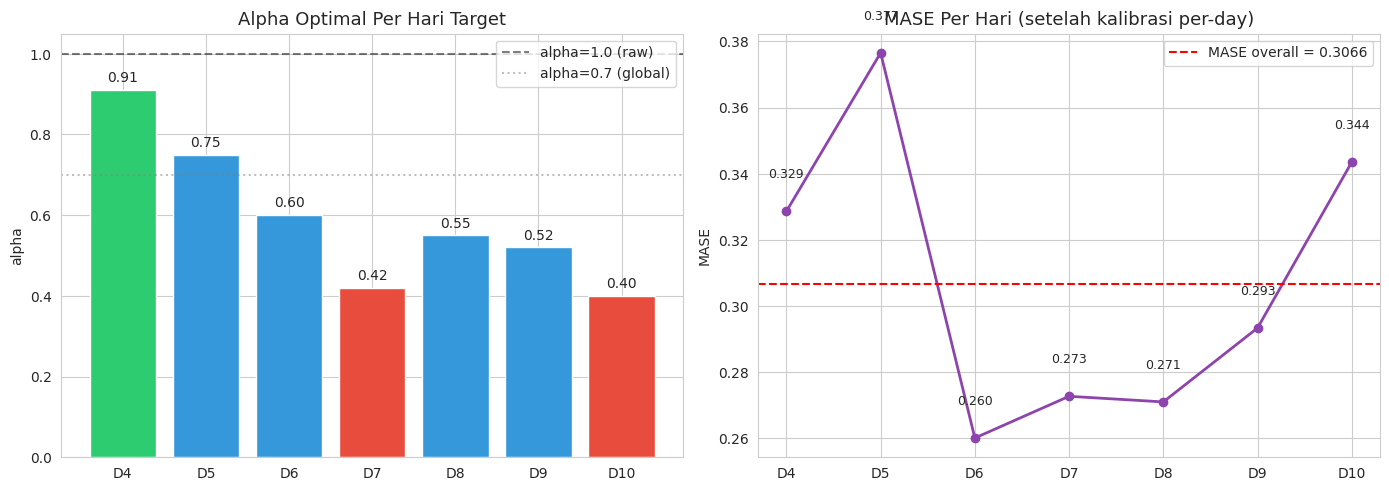

Interpretasi:
- Alpha TURUN dari D4 ke D10 = model over-predict lebih parah di hari jauh
- Artinya: model tidak tahu demand decay, jadi perlu koreksi makin besar
- MASE tertinggi di D5 (0.3766) = weekend peak paling susah diprediksi


In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel kiri: alpha per hari
days = [f"D{i}" for i in range(4, 11)]
alphas = [alpha_per_day[t] for t in target_cols]

axes[0].bar(days, alphas, color=["#e74c3c" if a < 0.5 else "#3498db" if a < 0.8 else "#2ecc71" for a in alphas])
axes[0].axhline(1.0, color="black", linestyle="--", alpha=0.5, label="alpha=1.0 (raw)")
axes[0].axhline(0.7, color="gray", linestyle=":", alpha=0.5, label="alpha=0.7 (global)")
axes[0].set_title("Alpha Optimal Per Hari Target", fontsize=13)
axes[0].set_ylabel("alpha")
axes[0].legend()
for i, (d, a) in enumerate(zip(days, alphas)):
    axes[0].text(i, a + 0.02, f"{a:.2f}", ha="center", fontsize=10)

# Panel kanan: MASE per hari
mase_per_day_vals = []
for j, t in enumerate(target_cols):
    mase_j = np.mean(np.abs(y_va[:, j] - pred_va[:, j] * alpha_per_day[t]) / scale_va)
    mase_per_day_vals.append(mase_j)

axes[1].plot(days, mase_per_day_vals, marker="o", linewidth=2, color="#8e44ad")
axes[1].axhline(0.3066, color="red", linestyle="--", label="MASE overall = 0.3066")
axes[1].set_title("MASE Per Hari (setelah kalibrasi per-day)", fontsize=13)
axes[1].set_ylabel("MASE")
axes[1].legend()
for i, m in enumerate(mase_per_day_vals):
    axes[1].text(i, m + 0.01, f"{m:.3f}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

print("Interpretasi:")
print("- Alpha TURUN dari D4 ke D10 = model over-predict lebih parah di hari jauh")
print("- Artinya: model tidak tahu demand decay, jadi perlu koreksi makin besar")
print("- MASE tertinggi di D5 (0.3766) = weekend peak paling susah diprediksi")

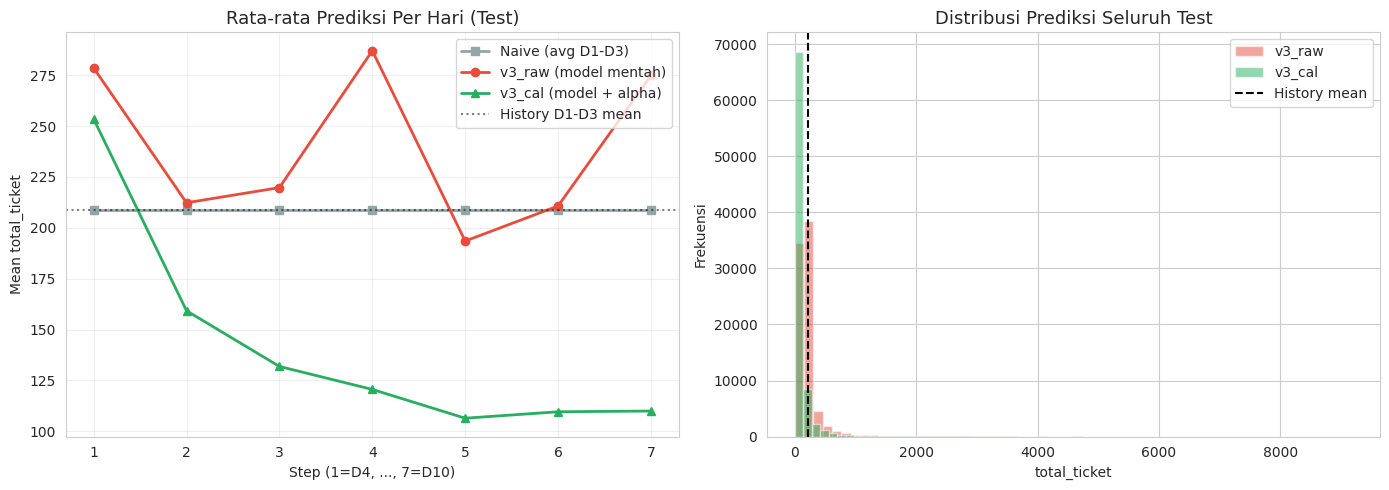

Interpretasi:
- Naive flat di ~209 (tidak tahu pola)
- v3_raw flat di ~240 (naik 15%, over-predict)
- v3_cal turun gradual dari D4 ke D10 (mengikuti pola decay)


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel kiri: rata-rata prediksi per step (D4-D10)
# Rebuild long format untuk 3 versi
def get_step_mean(pred_matrix):
    keys = X_te[K].copy()
    for j, t in enumerate(target_cols):
        keys[t] = pred_matrix[:, j]
    long = keys.melt(id_vars=K, value_vars=target_cols,
                     var_name="tcol", value_name="total_ticket")
    long["step"] = long["tcol"].str.replace("target_","").astype(int) - 3
    return long.groupby("step")["total_ticket"].mean()

# Naive per-step
naive_step = []
for step in range(1, 8):
    naive_step.append(test_history.groupby(K).head(3).groupby(K)["total_ticket"].mean().mean())
naive_step = np.array(naive_step)

step_raw = get_step_mean(pred_raw).values
step_cal = get_step_mean(pred_cal).values

steps = list(range(1, 8))
axes[0].plot(steps, naive_step, marker="s", linewidth=2, label="Naive (avg D1-D3)", color="#95a5a6")
axes[0].plot(steps, step_raw, marker="o", linewidth=2, label="v3_raw (model mentah)", color="#e74c3c")
axes[0].plot(steps, step_cal, marker="^", linewidth=2, label="v3_cal (model + alpha)", color="#27ae60")
axes[0].axhline(208.89, color="black", linestyle=":", alpha=0.5, label="History D1-D3 mean")
axes[0].set_title("Rata-rata Prediksi Per Hari (Test)", fontsize=13)
axes[0].set_xlabel("Step (1=D4, ..., 7=D10)")
axes[0].set_ylabel("Mean total_ticket")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel kanan: distribusi prediksi (histogram)
axes[1].hist(pred_raw.reshape(-1), bins=60, alpha=0.5, label="v3_raw", color="#e74c3c")
axes[1].hist(pred_cal.reshape(-1), bins=60, alpha=0.5, label="v3_cal", color="#27ae60")
axes[1].axvline(208.89, color="black", linestyle="--", label="History mean")
axes[1].set_title("Distribusi Prediksi Seluruh Test", fontsize=13)
axes[1].set_xlabel("total_ticket")
axes[1].set_ylabel("Frekuensi")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Interpretasi:")
print("- Naive flat di ~209 (tidak tahu pola)")
print("- v3_raw flat di ~240 (naik 15%, over-predict)")
print("- v3_cal turun gradual dari D4 ke D10 (mengikuti pola decay)")

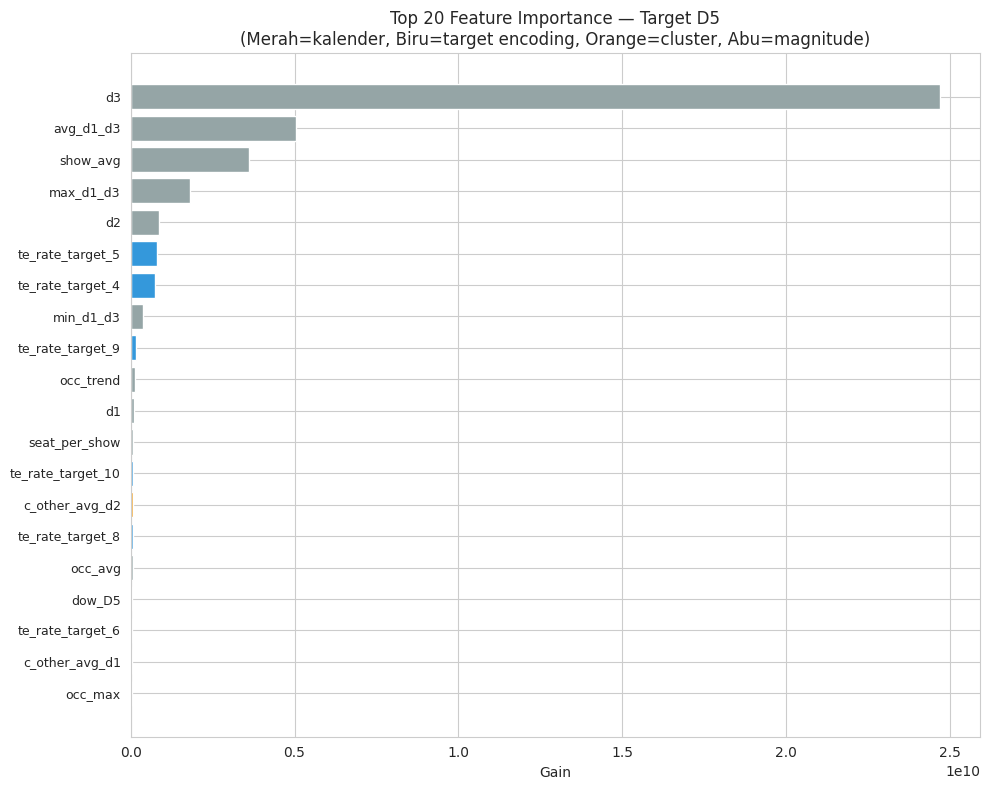

🚩 MASALAH: hampir semua bar ABU-ABU (magnitude).
   Fitur kalender (weekend/dow/holiday) TIDAK ADA di top-20.
   Artinya: model tidak belajar pola weekend, cuma copy skala D1-D3.


In [63]:
fig, ax = plt.subplots(figsize=(10, 8))

imp_top20 = imp.head(20).iloc[::-1]  # reverse untuk barh

colors = []
for f in imp_top20["feature"]:
    if "weekend_D" in f or "dow_D" in f or "holiday_D" in f:
        colors.append("#e74c3c")   # MERAH = fitur kalender (harus muncul!)
    elif "te_rate" in f:
        colors.append("#3498db")   # BIRU = target encoding
    elif "c_other" in f or "share_in_cluster" in f:
        colors.append("#f39c12")   # ORANGE = cluster
    else:
        colors.append("#95a5a6")   # ABU = magnitude

ax.barh(imp_top20["feature"], imp_top20["gain"], color=colors)
ax.set_title("Top 20 Feature Importance — Target D5\n(Merah=kalender, Biru=target encoding, Orange=cluster, Abu=magnitude)",
             fontsize=12)
ax.set_xlabel("Gain")
ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()
plt.show()

print("🚩 MASALAH: hampir semua bar ABU-ABU (magnitude).")
print("   Fitur kalender (weekend/dow/holiday) TIDAK ADA di top-20.")
print("   Artinya: model tidak belajar pola weekend, cuma copy skala D1-D3.")

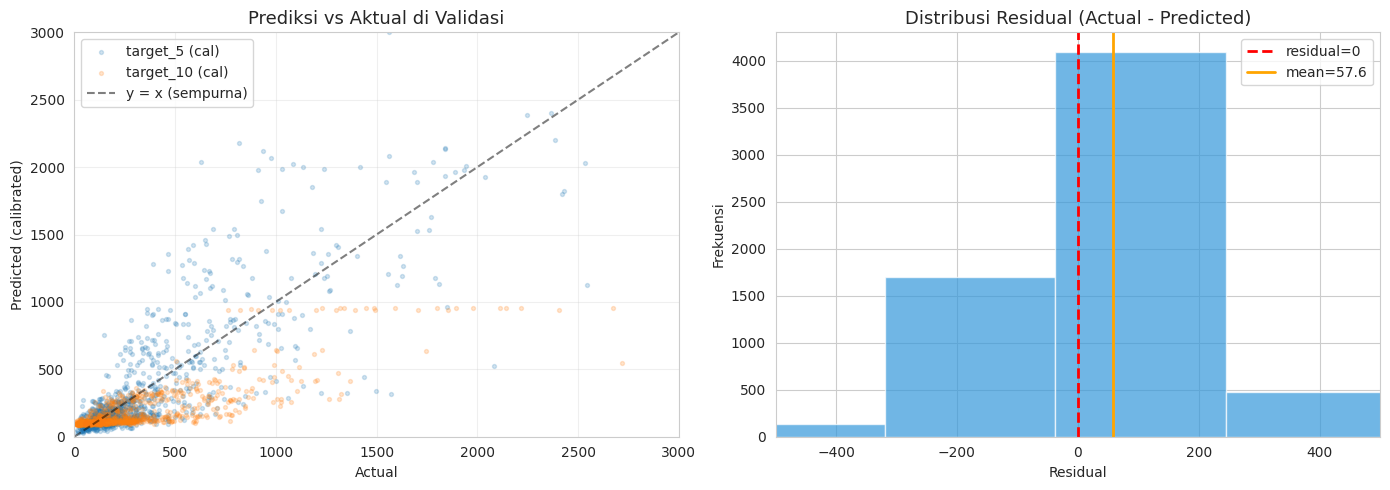

Mean residual: 57.60
Kalau >0: under-predict. Kalau <0: over-predict. 57.60 → under-predict


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel kiri: scatter pred vs actual untuk D5 dan D10
for j_show, t_show in [(1, "target_5"), (6, "target_10")]:
    axes[0].scatter(y_va[:, j_show], pred_va[:, j_show] * alpha_per_day[t_show],
                    alpha=0.2, s=8, label=f"{t_show} (cal)")

lim = max(y_va.max(), (pred_va * 1.5).max())
axes[0].plot([0, lim], [0, lim], "k--", alpha=0.5, label="y = x (sempurna)")
axes[0].set_xlim(0, min(lim, 3000))
axes[0].set_ylim(0, min(lim, 3000))
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted (calibrated)")
axes[0].set_title("Prediksi vs Aktual di Validasi", fontsize=13)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel kanan: residual distribution
residual = (y_va.reshape(-1) - (pred_va * np.array([alpha_per_day[t] for t in target_cols])).reshape(-1))
axes[1].hist(residual, bins=80, color="#3498db", alpha=0.7)
axes[1].axvline(0, color="red", linestyle="--", linewidth=2, label="residual=0")
axes[1].axvline(residual.mean(), color="orange", linestyle="-", linewidth=2,
                label=f"mean={residual.mean():.1f}")
axes[1].set_title("Distribusi Residual (Actual - Predicted)", fontsize=13)
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frekuensi")
axes[1].set_xlim(-500, 500)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Mean residual: {residual.mean():.2f}")
print(f"Kalau >0: under-predict. Kalau <0: over-predict. {residual.mean():.2f} → {'under' if residual.mean()>0 else 'over'}-predict")

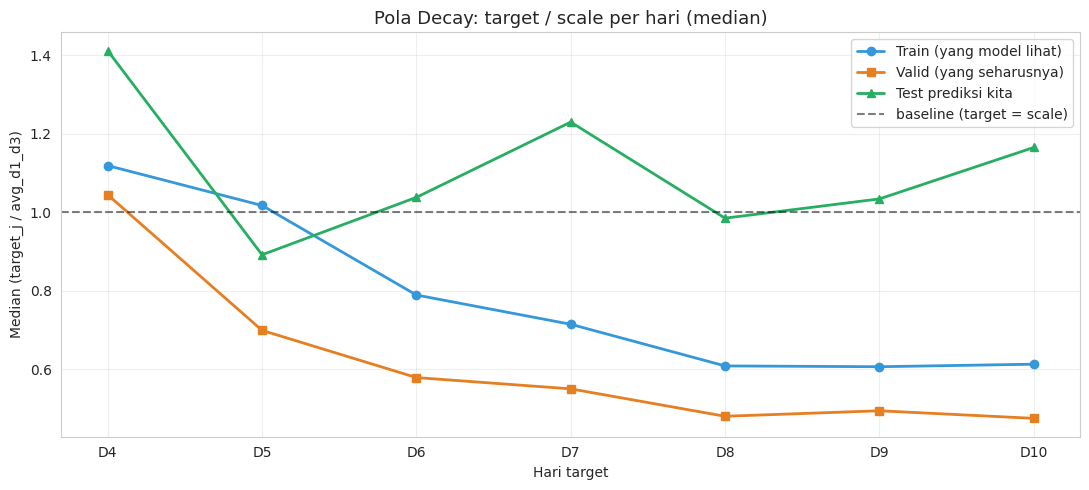

Interpretasi:
- Kalau kurva Train dan Valid BERBEDA → model dilatih di pola summer, valid pola berbeda
- Kurva Test harus DEKAT dengan Valid (bukan Train)
- Kalau test prediksi lebih flat dari valid → model tidak menangkap decay


In [65]:
fig, ax = plt.subplots(figsize=(11, 5))

# Dari train (yang model lihat)
profile_train = []
for t in target_cols:
    ratio = (tr_df[t] / tr_df["scale"]).median()
    profile_train.append(ratio)

# Dari valid
profile_valid = []
for t in target_cols:
    ratio = (va_df[t] / va_df["scale"]).median()
    profile_valid.append(ratio)

# Dari test (prediksi kita)
profile_test_cal = []
keys = X_te[K].copy()
for j, t in enumerate(target_cols):
    keys[t] = pred_cal[:, j]
keys["scale_test"] = X_te["scale"].values
for t in target_cols:
    profile_test_cal.append((keys[t] / keys["scale_test"]).median())

days = [f"D{i}" for i in range(4, 11)]
ax.plot(days, profile_train, marker="o", label="Train (yang model lihat)", linewidth=2, color="#3498db")
ax.plot(days, profile_valid, marker="s", label="Valid (yang seharusnya)", linewidth=2, color="#e67e22")
ax.plot(days, profile_test_cal, marker="^", label="Test prediksi kita", linewidth=2, color="#27ae60")
ax.axhline(1.0, color="black", linestyle="--", alpha=0.5, label="baseline (target = scale)")

ax.set_title("Pola Decay: target / scale per hari (median)", fontsize=13)
ax.set_ylabel("Median (target_j / avg_d1_d3)")
ax.set_xlabel("Hari target")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Interpretasi:")
print("- Kalau kurva Train dan Valid BERBEDA → model dilatih di pola summer, valid pola berbeda")
print("- Kurva Test harus DEKAT dengan Valid (bukan Train)")
print("- Kalau test prediksi lebih flat dari valid → model tidak menangkap decay")

In [66]:
# Profile decay di train (yang model LIHAT saat latih)
for t in target_cols:
    median_ratio = (tr_df[t] / tr_df["scale"]).median()
    print(f"{t}: median(target/scale) = {median_ratio:.3f}")

target_4: median(target/scale) = 1.119
target_5: median(target/scale) = 1.017
target_6: median(target/scale) = 0.789
target_7: median(target/scale) = 0.715
target_8: median(target/scale) = 0.608
target_9: median(target/scale) = 0.606
target_10: median(target/scale) = 0.613


In [67]:
# Bandingkan profile decay: train vs prediksi test
train_profile = []
test_profile = []

for j, t in enumerate(target_cols):
    train_profile.append((tr_df[t] / tr_df["scale"]).median())

keys_te = X_te[K].copy()
for j, t in enumerate(target_cols):
    keys_te[t] = pred_cal[:, j]
keys_te["scale"] = X_te["scale"].values
for t in target_cols:
    test_profile.append((keys_te[t] / keys_te["scale"]).median())

print("Hari | Train Profile | Test Pred Profile | Ratio")
for i, t in enumerate(target_cols):
    r = test_profile[i] / train_profile[i] if train_profile[i] > 0 else 0
    print(f"{t} | {train_profile[i]:.3f} | {test_profile[i]:.3f} | {r:.3f}")

Hari | Train Profile | Test Pred Profile | Ratio
target_4 | 1.119 | 1.412 | 1.262
target_5 | 1.017 | 0.892 | 0.876
target_6 | 0.789 | 1.038 | 1.316
target_7 | 0.715 | 1.230 | 1.721
target_8 | 0.608 | 0.985 | 1.619
target_9 | 0.606 | 1.034 | 1.706
target_10 | 0.613 | 1.165 | 1.902


In [68]:
# Apakah valid profile ≠ train profile? (ada shift musiman?)
for t in target_cols:
    tr_m = (tr_df[t] / tr_df["scale"]).median()
    va_m = (va_df[t] / va_df["scale"]).median()
    print(f"{t}: train={tr_m:.3f}, valid={va_m:.3f}, ratio={va_m/tr_m:.3f}")

target_4: train=1.119, valid=1.045, ratio=0.933
target_5: train=1.017, valid=0.699, ratio=0.687
target_6: train=0.789, valid=0.579, ratio=0.733
target_7: train=0.715, valid=0.550, ratio=0.770
target_8: train=0.608, valid=0.480, ratio=0.789
target_9: train=0.606, valid=0.494, ratio=0.815
target_10: train=0.613, valid=0.475, ratio=0.775


# DIBAWAH INI DA BEDA KODE DARI AWAL GUYS

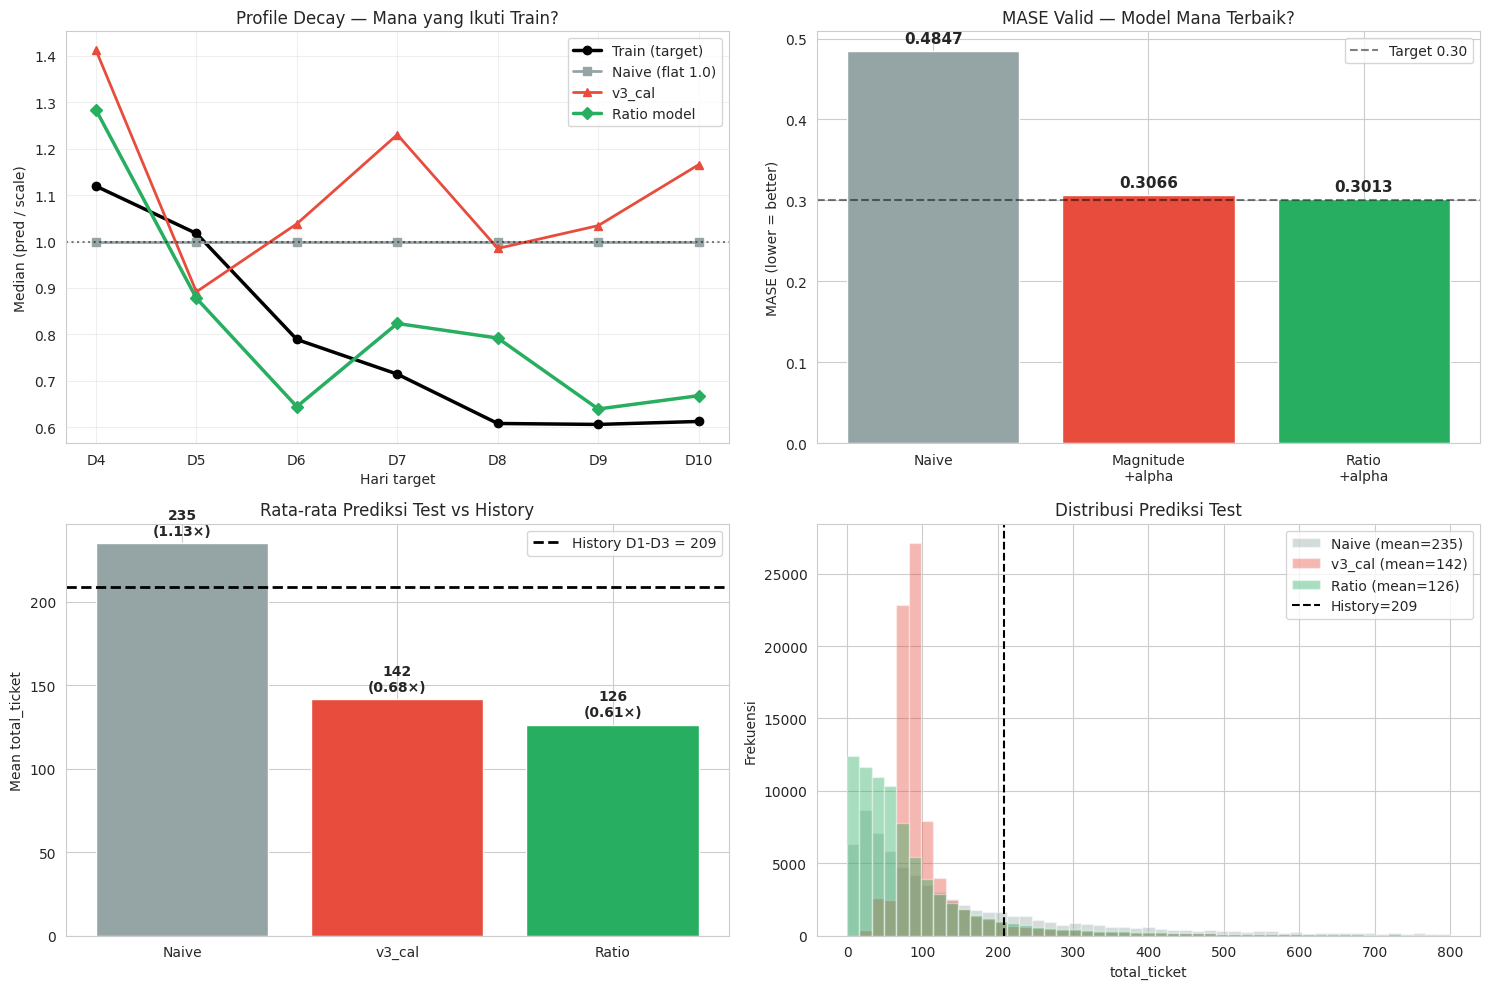

In [69]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

days = [f"D{i}" for i in range(4, 11)]

# === 1. Profile decay: 3 model vs train ===
ax = axes[0, 0]
train_profile = [(tr_df[t]/tr_df["scale"]).median() for t in target_cols]

def get_test_profile(pred_matrix):
    scales = X_te["scale"].values
    return [np.median(pred_matrix[:, j] / scales) for j in range(7)]

ratio_profile = get_test_profile(pred_te_mag)
cal_profile   = get_test_profile(pred_cal)
naive_profile = [1.0] * 7  # naive flat di 1.0

ax.plot(days, train_profile, marker="o", linewidth=2.5, label="Train (target)", color="black")
ax.plot(days, naive_profile, marker="s", linewidth=2, label="Naive (flat 1.0)", color="#95a5a6")
ax.plot(days, cal_profile, marker="^", linewidth=2, label="v3_cal", color="#e74c3c")
ax.plot(days, ratio_profile, marker="D", linewidth=2.5, label="Ratio model", color="#27ae60")

ax.axhline(1.0, color="black", linestyle=":", alpha=0.5)
ax.set_title("Profile Decay — Mana yang Ikuti Train?", fontsize=12)
ax.set_ylabel("Median (pred / scale)")
ax.set_xlabel("Hari target")
ax.legend()
ax.grid(alpha=0.3)

# === 2. Perbandingan MASE valid ===
ax = axes[0, 1]
models_names = ["Naive", "Magnitude\n+alpha", "Ratio\n+alpha"]
mase_vals = [0.4847, 0.3066, 0.3013]
colors = ["#95a5a6", "#e74c3c", "#27ae60"]
bars = ax.bar(models_names, mase_vals, color=colors)
ax.axhline(0.30, color="black", linestyle="--", alpha=0.5, label="Target 0.30")
for bar, val in zip(bars, mase_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.4f}",
            ha="center", fontsize=11, fontweight="bold")
ax.set_title("MASE Valid — Model Mana Terbaik?", fontsize=12)
ax.set_ylabel("MASE (lower = better)")
ax.legend()

# === 3. Prediksi vs History D1-D3 (magnitude) ===
ax = axes[1, 0]
hist_mean = 208.89

ratio_mean = pred_te_mag.mean()
cal_mean   = pred_cal.mean()
naive_mean = sub_naive["total_ticket"].mean()

ax.axhline(hist_mean, color="black", linestyle="--", linewidth=2, label=f"History D1-D3 = {hist_mean:.0f}")

bars = ax.bar(["Naive", "v3_cal", "Ratio"], [naive_mean, cal_mean, ratio_mean],
              color=["#95a5a6", "#e74c3c", "#27ae60"])
for bar, val in zip(bars, [naive_mean, cal_mean, ratio_mean]):
    ratio_vs_hist = val / hist_mean
    ax.text(bar.get_x() + bar.get_width()/2, val + 5,
            f"{val:.0f}\n({ratio_vs_hist:.2f}×)", ha="center", fontsize=10, fontweight="bold")
ax.set_title("Rata-rata Prediksi Test vs History", fontsize=12)
ax.set_ylabel("Mean total_ticket")
ax.legend()

# === 4. Distribusi prediksi per model ===
ax = axes[1, 1]
bins = np.linspace(0, 800, 50)
ax.hist(sub_naive["total_ticket"], bins=bins, alpha=0.4, label=f"Naive (mean={naive_mean:.0f})", color="#95a5a6")
ax.hist(pred_cal.reshape(-1),       bins=bins, alpha=0.4, label=f"v3_cal (mean={cal_mean:.0f})", color="#e74c3c")
ax.hist(pred_te_mag.reshape(-1),    bins=bins, alpha=0.4, label=f"Ratio (mean={ratio_mean:.0f})", color="#27ae60")
ax.axvline(hist_mean, color="black", linestyle="--", label=f"History={hist_mean:.0f}")
ax.set_title("Distribusi Prediksi Test", fontsize=12)
ax.set_xlabel("total_ticket")
ax.set_ylabel("Frekuensi")
ax.legend()

plt.tight_layout()
plt.show()

# PISAH LAGI

In [70]:
# ============================================================
#  GENERATE SUBMISSION RATIO MODEL
#  Pakai pred_te_mag yang sudah dihitung di cell ratio model
# ============================================================

def make_submission(pred_matrix, filename):
    keys = X_te[K].copy()
    for j, t in enumerate(target_cols):
        keys[t] = pred_matrix[:, j]
    long = keys.melt(id_vars=K, value_vars=target_cols,
                     var_name="tcol", value_name="total_ticket")
    long["step"] = long["tcol"].str.replace("target_", "").astype(int) - 3
    tt = test.copy().sort_values("date_show")
    tt["step"] = tt.groupby(K).cumcount() + 1
    sub = tt.merge(long[K + ["step","total_ticket"]], on=K + ["step"], how="left")
    submission = sample_sub[["id"]].merge(sub[["id","total_ticket"]], on="id", how="left")
    submission["total_ticket"] = submission["total_ticket"].fillna(0)
    submission.to_csv(filename, index=False)
    s = pd.read_csv(filename)
    assert s.shape == sample_sub.shape, f"Shape mismatch: {s.shape}"
    assert (s["id"].values == sample_sub["id"].values).all(), "ID mismatch"
    assert s["total_ticket"].notna().all(), "Ada NaN"
    assert (s["total_ticket"] >= 0).all(), "Ada negatif"
    print(f"✅ {filename}")
    print(f"   shape : {s.shape}")
    print(f"   mean  : {s['total_ticket'].mean():.2f}")
    print(f"   max   : {s['total_ticket'].max():.0f}")
    print(f"   min   : {s['total_ticket'].min():.2f}")
    print()

# Bikin file dari pred_te_mag (hasil ratio model + alpha per-hari)
make_submission(pred_te_mag, "submission_ratio_cal.csv")

# Cek juga file lain yang sudah ada
print("=== File yang sudah ada ===")
import os
for f in ["submission_naive.csv", "submission_v3_cal.csv",
          "submission_v3_raw.csv", "submission_ratio_cal.csv"]:
    if os.path.exists(f):
        print(f"  ✅ {f}")
    else:
        print(f"  ❌ {f} (belum dibuat)")

✅ submission_ratio_cal.csv
   shape : (72611, 2)
   mean  : 141.29
   max   : 34384
   min   : 0.78

=== File yang sudah ada ===
  ✅ submission_naive.csv
  ✅ submission_v3_cal.csv
  ✅ submission_v3_raw.csv
  ✅ submission_ratio_cal.csv


In [71]:
print("pred_te_mag ada?", "pred_te_mag" in dir())
print("shape:", pred_te_mag.shape if "pred_te_mag" in dir() else "TIDAK ADA")

pred_te_mag ada? True
shape: (11823, 7)


In [72]:
# === REBUILD pred_te_mag kalau hilang ===
# Ini ringkas dari kode ratio model sebelumnya

# 1. Train ratio models
for t in target_cols:
    tr_df[f"ratio_{t}"] = tr_df[t] / tr_df["scale"]
    va_df[f"ratio_{t}"] = va_df[t] / va_df["scale"]
ratio_cols = [f"ratio_{t}" for t in target_cols]

params = dict(objective="regression", metric="mae", learning_rate=0.03,
              num_leaves=63, min_data_in_leaf=20, feature_fraction=0.85,
              bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
              seed=SEED, verbosity=-1)

models_ratio, best_iters_ratio = {}, {}
for j, rc in enumerate(ratio_cols):
    dtr = lgb.Dataset(X_tr, tr_df[rc].values, categorical_feature=cat_cols)
    dva = lgb.Dataset(X_va, va_df[rc].values, reference=dtr)
    m = lgb.train(params, dtr, num_boost_round=2000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    models_ratio[rc] = m
    best_iters_ratio[rc] = m.best_iteration

# 2. Prediksi test di ratio-space
pred_te_ratio = np.zeros((len(X_te_full), len(target_cols)))
for j, rc in enumerate(ratio_cols):
    pred_te_ratio[:, j] = models_ratio[rc].predict(X_te_full,
                                                   num_iteration=best_iters_ratio[rc])
pred_te_ratio = np.clip(pred_te_ratio, 0, None)

# 3. Apply alpha ratio (dari cell sebelumnya, atau fallback 1.0)
try:
    alpha_ratio
except NameError:
    alpha_ratio = {rc: 1.0 for rc in ratio_cols}
    print("⚠️  alpha_ratio tidak ada, pakai 1.0")

pred_te_ratio_cal = np.zeros_like(pred_te_ratio)
for j, rc in enumerate(ratio_cols):
    pred_te_ratio_cal[:, j] = np.clip(pred_te_ratio[:, j] * alpha_ratio[rc], 0, None)

# 4. Convert ke magnitude
scale_te = X_te["scale"].values
pred_te_mag = np.clip(pred_te_ratio_cal * scale_te[:, None], 0, None)

print(f"pred_te_mag shape: {pred_te_mag.shape}")
print(f"mean: {pred_te_mag.mean():.2f}")

pred_te_mag shape: (11823, 7)
mean: 126.45


In [73]:
# Cek apakah ratio_cal prediksi juga konsisten per-baris (bukan cuma median)
sample_idx = [0, 50, 100, 500, 1000]

print("Sample prediksi per-baris:")
print(f"{'idx':<5} {'hist_avg':<10} {'ratio_cal_D4':<15} {'ratio_cal_D10':<15}")
for idx in sample_idx:
    hist = X_te.iloc[idx][["d1","d2","d3"]].mean()
    p4  = pred_te_mag[idx, 0]
    p10 = pred_te_mag[idx, 6]
    print(f"{idx:<5} {hist:<10.1f} {p4:<15.1f} {p10:<15.1f}")

# Rasio D4/hist dan D10/hist harus konsisten lintas baris

Sample prediksi per-baris:
idx   hist_avg   ratio_cal_D4    ratio_cal_D10  
0     71.3       53.9            45.2           
50    235.3      248.0           104.6          
100   28.7       43.8            23.7           
500   10.7       14.7            8.9            
1000  2349.0     2515.8          924.4          


# AKU CEK OVERFIT HABIS HABISAN

In [77]:
print("="*70)
print("DIAGNOSTIC #1 — Train vs Valid MASE (gap overfit)")
print("="*70)

train_maes, valid_maes = [], []

for j, rc in enumerate(ratio_cols):
    # In-sample: prediksi di train
    pred_tr = np.clip(models_ratio[rc].predict(X_tr), 0, None)
    mae_tr  = np.mean(np.abs(tr_df[rc].values - pred_tr))

    # Out-of-sample: prediksi di valid
    pred_va = np.clip(models_ratio[rc].predict(X_va), 0, None)
    mae_va  = np.mean(np.abs(va_df[rc].values - pred_va))

    train_maes.append(mae_tr)
    valid_maes.append(mae_va)
    print(f"  {rc}: train={mae_tr:.4f}  valid={mae_va:.4f}  gap={mae_va-mae_tr:+.4f}")

avg_train = np.mean(train_maes)
avg_valid = np.mean(valid_maes)
gap = avg_valid - avg_train

print(f"\n  Train MASE (in-sample) : {avg_train:.4f}")
print(f"  Valid MASE (out-sample): {avg_valid:.4f}")
print(f"  GAP                    : {gap:+.4f}")
print()

if gap < 0.05:
    print("  ✅ Sehat — model tidak overfit")
elif gap < 0.15:
    print("  🟡 Overfit ringan — masih acceptable")
elif gap < 0.30:
    print("  🟠 Overfit sedang — pertimbangkan regularisasi")
else:
    print("  🚩 Overfit BERAT — model hafal train")

DIAGNOSTIC #1 — Train vs Valid MASE (gap overfit)
  ratio_target_4: train=0.1419  valid=0.3276  gap=+0.1857
  ratio_target_5: train=0.0732  valid=0.4079  gap=+0.3347
  ratio_target_6: train=0.0633  valid=0.2893  gap=+0.2260
  ratio_target_7: train=0.1444  valid=0.2886  gap=+0.1443
  ratio_target_8: train=0.1490  valid=0.2944  gap=+0.1454
  ratio_target_9: train=0.1817  valid=0.3257  gap=+0.1440
  ratio_target_10: train=0.1849  valid=0.3187  gap=+0.1338

  Train MASE (in-sample) : 0.1340
  Valid MASE (out-sample): 0.3217
  GAP                    : +0.1877

  🟠 Overfit sedang — pertimbangkan regularisasi


DIAGNOSTIC #2 — Learning Curve (train size vs error)
  size=  300: train=0.0130  valid=0.4533  gap=+0.4403
  size=  800: train=0.0061  valid=0.5402  gap=+0.5341
  size= 1500: train=0.0030  valid=0.4202  gap=+0.4173
  size= 2500: train=0.0027  valid=0.3942  gap=+0.3914
  size= 2667: train=0.0032  valid=0.3923  gap=+0.3891


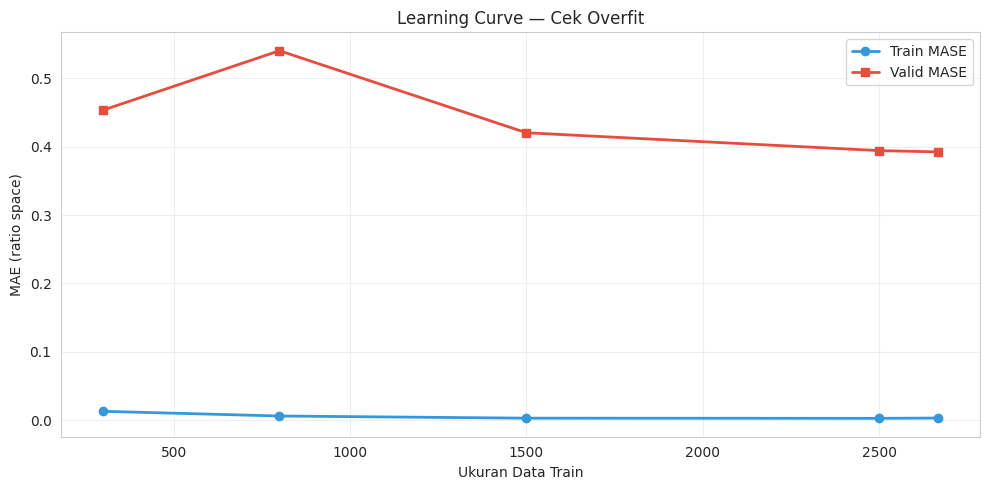


  Gap pada size terbesar : +0.3891
  🎯 Kalau gap menyempit → tidak overfit.
  🚩 Kalau gap TETAP BESAR → overfit struktural.


In [78]:
print("="*70)
print("DIAGNOSTIC #2 — Learning Curve (train size vs error)")
print("="*70)

# Fokus 1 model sebagai sample
rc_sample = "ratio_target_5"  # D5, biasanya paling penting

sizes = [300, 800, 1500, 2500, len(tr_df)]
train_curve, valid_curve = [], []

for size in sizes:
    if size > len(tr_df): continue
    sub = tr_df.sample(n=size, random_state=SEED)
    X_sub = X_tr.loc[sub.index]  # ambil baris yang sama
    y_sub = sub[rc_sample].values

    m = lgb.LGBMRegressor(
        objective="regression", metric="mae",
        learning_rate=0.03, n_estimators=2000, num_leaves=63,
        min_child_samples=20, feature_fraction=0.85,
        bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
        random_state=SEED, verbosity=-1
    )
    m.fit(X_sub, y_sub, categorical_feature=cat_cols)

    pred_tr = np.clip(m.predict(X_sub), 0, None)
    pred_va = np.clip(m.predict(X_va), 0, None)

    train_curve.append(np.mean(np.abs(y_sub - pred_tr)))
    valid_curve.append(np.mean(np.abs(va_df[rc_sample].values - pred_va)))
    print(f"  size={size:>5}: train={train_curve[-1]:.4f}  valid={valid_curve[-1]:.4f}  gap={valid_curve[-1]-train_curve[-1]:+.4f}")

# Plot
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
used_sizes = sizes[:len(train_curve)]
plt.plot(used_sizes, train_curve, marker="o", linewidth=2, label="Train MASE", color="#3498db")
plt.plot(used_sizes, valid_curve, marker="s", linewidth=2, label="Valid MASE", color="#e74c3c")
plt.xlabel("Ukuran Data Train"); plt.ylabel("MAE (ratio space)")
plt.title("Learning Curve — Cek Overfit"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n  Gap pada size terbesar : {valid_curve[-1]-train_curve[-1]:+.4f}")
print("  🎯 Kalau gap menyempit → tidak overfit.")
print("  🚩 Kalau gap TETAP BESAR → overfit struktural.")

In [79]:
print("="*70)
print("DIAGNOSTIC #3 — Bandingkan dengan Naive Baseline")
print("="*70)

# Naive ratio = 1.0 (artinya target = scale)
naive_mae = np.mean(np.abs(va_df[ratio_cols].values - 1.0))
model_mae = np.mean(np.abs(va_df[ratio_cols].values - pred_va_ratio))

# Naive per hari
print("  Per hari:")
for j, rc in enumerate(ratio_cols):
    naive_j = np.mean(np.abs(va_df[rc].values - 1.0))
    model_j = np.mean(np.abs(va_df[rc].values - pred_va_ratio[:, j]))
    print(f"    {rc}: naive={naive_j:.4f}  model={model_j:.4f}  delta={naive_j-model_j:+.4f}")

print(f"\n  Naive overall : {naive_mae:.4f}")
print(f"  Model overall : {model_mae:.4f}")
print(f"  Delta         : {naive_mae - model_mae:+.4f}")
print()

delta = naive_mae - model_mae
if delta > 0.15:
    print("  ✅ Model JAUH lebih baik dari naive")
elif delta > 0.05:
    print("  ✅ Model lebih baik dari naive")
elif delta > 0:
    print("  🟡 Model sedikit lebih baik — mungkin tidak terlalu berguna")
else:
    print("  🚩 Model LEBIH JELEK dari naive — ada masalah serius")

DIAGNOSTIC #3 — Bandingkan dengan Naive Baseline
  Per hari:
    ratio_target_4: naive=0.3975  model=0.3276  delta=+0.0699
    ratio_target_5: naive=0.4929  model=0.4079  delta=+0.0850
    ratio_target_6: naive=0.4511  model=0.2893  delta=+0.1618
    ratio_target_7: naive=0.4734  model=0.2886  delta=+0.1847
    ratio_target_8: naive=0.5256  model=0.2944  delta=+0.2312
    ratio_target_9: naive=0.5198  model=0.3257  delta=+0.1942
    ratio_target_10: naive=0.5326  model=0.3187  delta=+0.2139

  Naive overall : 0.4847
  Model overall : 0.3217
  Delta         : +0.1630

  ✅ Model JAUH lebih baik dari naive


In [80]:
print("="*70)
print("DIAGNOSTIC #4 — Feature Importance (cek fitur dominan)")
print("="*70)

# Fokus model D5
rc_check = "ratio_target_5"
imp = models_ratio[rc_check].feature_importance(importance_type="gain")
imp_series = pd.Series(imp, index=models_ratio[rc_check].feature_name()).sort_values(ascending=False)
imp_norm = imp_series / imp_series.sum()

print(f"\n  Top-15 fitur untuk model {rc_check}:")
print("  " + "-"*60)
for feat, val in imp_norm.head(15).items():
    bar = "█" * int(val * 100)
    flag = " 🚩" if val > 0.15 else ""
    print(f"  {feat:<25} {val*100:>5.1f}%  {bar}{flag}")

top1 = imp_norm.iloc[0]
top3_sum = imp_norm.head(3).sum()
top10_sum = imp_norm.head(10).sum()

print(f"\n  Top-1 gain   : {top1*100:.1f}%")
print(f"  Top-3 gain   : {top3_sum*100:.1f}%")
print(f"  Top-10 gain  : {top10_sum*100:.1f}%")
print()

if top1 > 0.20:
    print(f"  🚩 Top-1 fitur '{imp_norm.index[0]}' mendominasi ({top1*100:.1f}%)")
elif top3_sum > 0.60:
    print(f"  🟠 Top-3 fitur mendominasi ({top3_sum*100:.1f}%)")
else:
    print("  ✅ Importance tersebar merata")

# Distribusi fitur "mati"
n_dead = (imp_norm < 0.001).sum()
print(f"\n  Fitur dengan gain < 0.1%: {n_dead}/{len(imp_norm)}")

DIAGNOSTIC #4 — Feature Importance (cek fitur dominan)

  Top-15 fitur untuk model ratio_target_5:
  ------------------------------------------------------------
  te_rate_target_5           32.7%  ████████████████████████████████ 🚩
  d1                          5.9%  █████
  te_rate_target_9            5.8%  █████
  d2                          4.1%  ████
  te_rate_target_6            3.8%  ███
  min_d1_d3                   3.5%  ███
  te_rate_target_4            3.3%  ███
  trend_d1_d3                 3.3%  ███
  avg_d1_d3                   3.3%  ███
  occ_avg                     3.2%  ███
  share_in_cluster            2.7%  ██
  occ_max                     2.7%  ██
  seat_per_show               2.7%  ██
  ratio_d3_d1                 2.6%  ██
  occ_trend                   2.2%  ██

  Top-1 gain   : 32.7%
  Top-3 gain   : 44.4%
  Top-10 gain  : 68.9%

  🚩 Top-1 fitur 'te_rate_target_5' mendominasi (32.7%)

  Fitur dengan gain < 0.1%: 19/56


In [81]:
print("="*70)
print("DIAGNOSTIC #5 — Noise Test (target di-shuffle)")
print("="*70)

rc_check = "ratio_target_5"

# Shuffle target train
tr_shuffled = tr_df.copy()
tr_shuffled[rc_check] = tr_shuffled[rc_check].sample(frac=1, random_state=SEED).values

m_shuffle = lgb.LGBMRegressor(
    objective="regression", metric="mae",
    learning_rate=0.03, n_estimators=500, num_leaves=31,
    random_state=SEED, verbosity=-1
)
m_shuffle.fit(X_tr, tr_shuffled[rc_check].values, categorical_feature=cat_cols)

pred_tr_shuf = np.clip(m_shuffle.predict(X_tr), 0, None)
pred_va_shuf = np.clip(m_shuffle.predict(X_va), 0, None)

mae_tr_shuf = np.mean(np.abs(tr_shuffled[rc_check].values - pred_tr_shuf))
mae_va_shuf = np.mean(np.abs(va_df[rc_check].values - pred_va_shuf))
mae_va_naive = np.mean(np.abs(va_df[rc_check].values - 1.0))

print(f"  Train MASE (target shuffled) : {mae_tr_shuf:.4f}")
print(f"  Valid MASE (target shuffled) : {mae_va_shuf:.4f}")
print(f"  Valid MASE naive             : {mae_va_naive:.4f}")
print()

if mae_va_shuf < mae_va_naive * 0.9:
    print("  🚩 Valid MASE < 90% naive — ada LEAKAGE!")
elif mae_va_shuf < mae_va_naive:
    print("  🟡 Valid sedikit lebih baik dari naive — cek lagi")
else:
    print("  ✅ Valid MASE ≥ naive — tidak ada leakage")

DIAGNOSTIC #5 — Noise Test (target di-shuffle)
  Train MASE (target shuffled) : 0.1680
  Valid MASE (target shuffled) : 0.5904
  Valid MASE naive             : 0.4929

  ✅ Valid MASE ≥ naive — tidak ada leakage


In [82]:
print("="*70)
print("DIAGNOSTIC #6 — Residual per Segmen")
print("="*70)

# Siapkan dataframe untuk analisa
V_diag = pd.DataFrame({
    "ratio_true": va_df[ratio_cols].values.reshape(-1),
    "ratio_pred": pred_va_ratio.reshape(-1),
    "k":          np.tile(va_df["date_D1"].values, len(ratio_cols)),  # placeholder
})

# Buat k dari target_cols index
k_vals = []
for j, rc in enumerate(ratio_cols):
    k_vals.extend([j+4] * len(va_df))
V_diag["k"] = k_vals
V_diag["abs_err"] = np.abs(V_diag.ratio_true - V_diag.ratio_pred)
V_diag["scale"] = np.tile(scale_va, len(ratio_cols))

# Error per hari target
print("\n  MAE per hari target:")
for k in range(4, 11):
    mae_k = V_diag[V_diag.k == k].abs_err.mean()
    print(f"    D{k}: {mae_k:.4f}")

# Error per scale bucket
V_diag["scale_bin"] = pd.cut(V_diag.scale, [0, 50, 100, 200, 500, 1000, 10000])
print("\n  MAE per bucket scale (D1-D3 avg):")
for bin_name, group in V_diag.groupby("scale_bin"):
    if len(group) > 0:
        print(f"    {bin_name}: MAE={group.abs_err.mean():.4f}  n={len(group)}")

# Error per genre (kalau genre ada)
if "genre_main" in va_df.columns:
    genre_vals = []
    for j, rc in enumerate(ratio_cols):
        genre_vals.extend(va_df["genre_main"].values)
    V_diag["genre"] = genre_vals
    print("\n  MAE per genre (top 5):")
    genre_err = V_diag.groupby("genre").abs_err.agg(["mean", "size"])
    genre_err = genre_err[genre_err["size"] > 100].sort_values("mean", ascending=False)
    print(genre_err.head(5).round(4))

DIAGNOSTIC #6 — Residual per Segmen

  MAE per hari target:
    D4: 0.3381
    D5: 0.3350
    D6: 0.3972
    D7: 0.2831
    D8: 0.2599
    D9: 0.3006
    D10: 0.3382

  MAE per bucket scale (D1-D3 avg):
    (0, 50]: MAE=0.3200  n=98
    (50, 100]: MAE=0.3248  n=371
    (100, 200]: MAE=0.3253  n=1617
    (200, 500]: MAE=0.3243  n=2415
    (500, 1000]: MAE=0.3182  n=980
    (1000, 10000]: MAE=0.3151  n=1267

  MAE per genre (top 5):
             mean  size
genre                  
Crime      0.3545   672
Comedy     0.3375   476
Drama      0.3276  1400
Animation  0.3205   798
Horror     0.3186  2016


DIAGNOSTIC #7 — Distribusi Residual (Bias Sistematis)
  Mean residual     : -0.0230
  Median residual   : -0.1098
  Std residual      : 0.4501
  Skewness          : +1.6741
  % residual > 0    : 38.3%



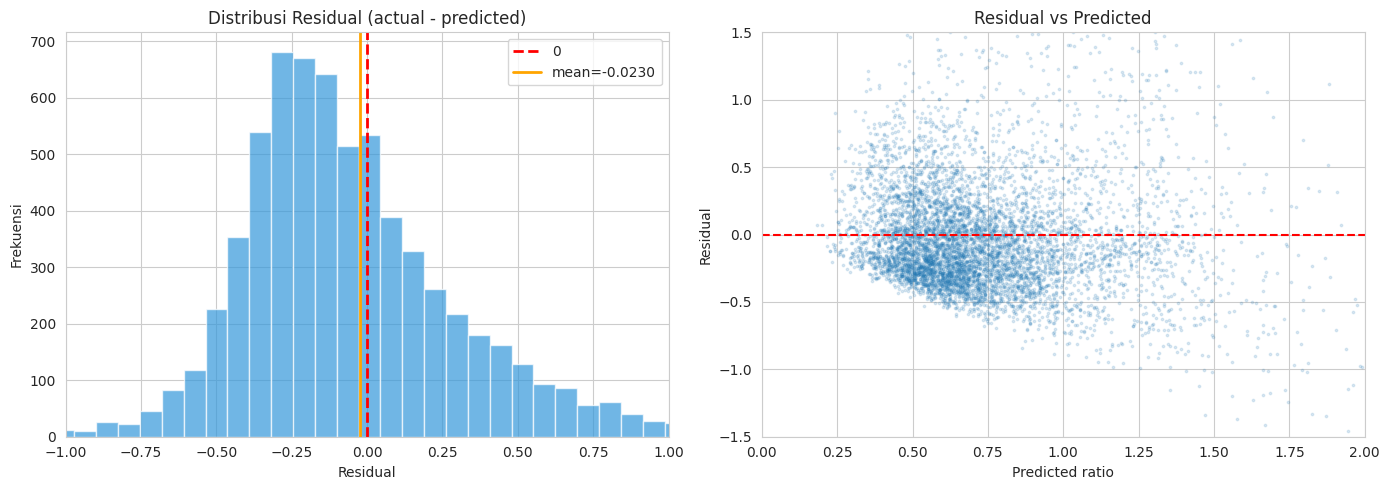

  🎯 Interpretasi:
    🟡 Model over-predict (residual mean -0.023)

    Residual mean saat pred > 1.0 : -0.0232
    Residual mean saat pred < 0.5 : +0.0590
    🎯 Kalau dua-duanya positif → over-predict di tail.
    🎯 Kalau dua-duanya negatif → under-predict di tail.


In [83]:
print("="*70)
print("DIAGNOSTIC #7 — Distribusi Residual (Bias Sistematis)")
print("="*70)

residual = (va_df[ratio_cols].values - pred_va_ratio).reshape(-1)

print(f"  Mean residual     : {residual.mean():+.4f}")
print(f"  Median residual   : {np.median(residual):+.4f}")
print(f"  Std residual      : {residual.std():.4f}")
print(f"  Skewness          : {pd.Series(residual).skew():+.4f}")
print(f"  % residual > 0    : {(residual > 0).mean()*100:.1f}%")
print()

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residual, bins=80, color="#3498db", alpha=0.7)
axes[0].axvline(0, color="red", linestyle="--", linewidth=2, label="0")
axes[0].axvline(residual.mean(), color="orange", linewidth=2, label=f"mean={residual.mean():+.4f}")
axes[0].set_title("Distribusi Residual (actual - predicted)")
axes[0].set_xlabel("Residual"); axes[0].set_ylabel("Frekuensi")
axes[0].legend(); axes[0].set_xlim(-1, 1)

# Residual vs predicted
axes[1].scatter(pred_va_ratio.reshape(-1), residual, alpha=0.15, s=3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual vs Predicted")
axes[1].set_xlabel("Predicted ratio"); axes[1].set_ylabel("Residual")
axes[1].set_xlim(0, 2); axes[1].set_ylim(-1.5, 1.5)

plt.tight_layout(); plt.show()

print("  🎯 Interpretasi:")
if abs(residual.mean()) < 0.02:
    print("    ✅ Residual centered ~0 — model tidak bias")
elif residual.mean() > 0:
    print(f"    🟡 Model under-predict (residual mean {residual.mean():+.3f})")
else:
    print(f"    🟡 Model over-predict (residual mean {residual.mean():+.3f})")

# Pola sistematis
pred_flat = pred_va_ratio.reshape(-1)
high_mask = pred_flat > 1.0
low_mask  = pred_flat < 0.5
if high_mask.sum() > 10 and low_mask.sum() > 10:
    print(f"\n    Residual mean saat pred > 1.0 : {residual[high_mask].mean():+.4f}")
    print(f"    Residual mean saat pred < 0.5 : {residual[low_mask].mean():+.4f}")
    print("    🎯 Kalau dua-duanya positif → over-predict di tail.")
    print("    🎯 Kalau dua-duanya negatif → under-predict di tail.")